In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

df=pd.read_csv('business_data.csv')
df.head()

,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0


In [2]:
numeric=['Tenure','MonthlyCharges','TotalCharges','SeniorCitizen','Churn']
summary=df[numeric].describe().T
summary['median']=df[numeric].median()
summary['mode']=[df[c].mode().iloc[0] for c in numeric]
summary['variance']=df[numeric].var()
summary['skewness']=df[numeric].skew()
summary

,count,mean,std,min,25%,50%,75%,max,median,mode,variance,skewness
Tenure,500.0,36.532,20.667057,1.0,19.00,37.0,54.00,71.0,37.0,3,4.271272e+02,-0.090733
MonthlyCharges,500.0,113.636,51.799903,20.0,67.00,115.0,158.00,199.0,115.0,115,2.683230e+03,-0.088597
TotalCharges,500.0,4237.882,2260.619837,159.0,2237.25,4182.5,6266.75,7992.0,4182.5,4023,5.110402e+06,-0.026606
SeniorCitizen,500.0,0.498,0.500497,0.0,0.00,0.0,1.00,1.0,0.0,0,2.504970e-01,0.008024
Churn,500.0,0.106,0.308146,0.0,0.00,0.0,0.00,1.0,0.0,0,9.495391e-02,2.567500


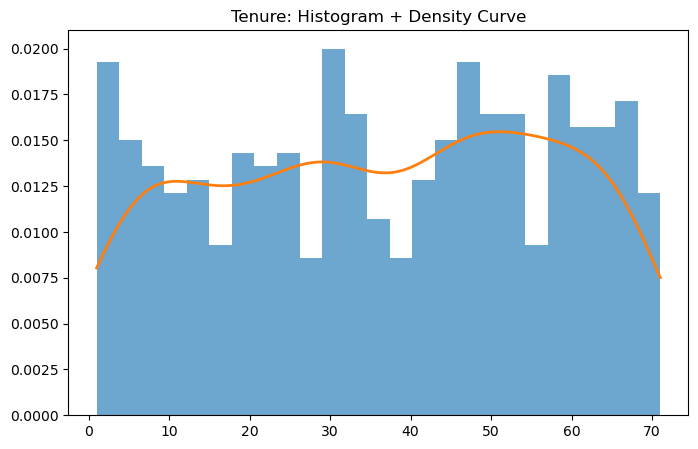

Tenure ShapiroResult(statistic=0.9496110926327249, pvalue=5.102605604030572e-12)


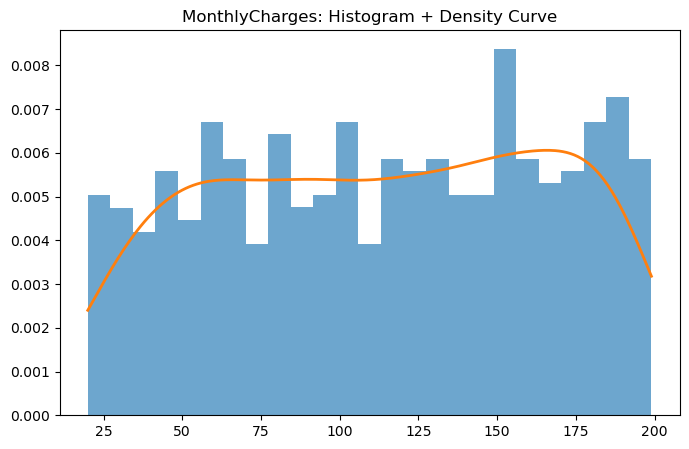

MonthlyCharges ShapiroResult(statistic=0.9520227046235356, pvalue=1.1492265093812981e-11)


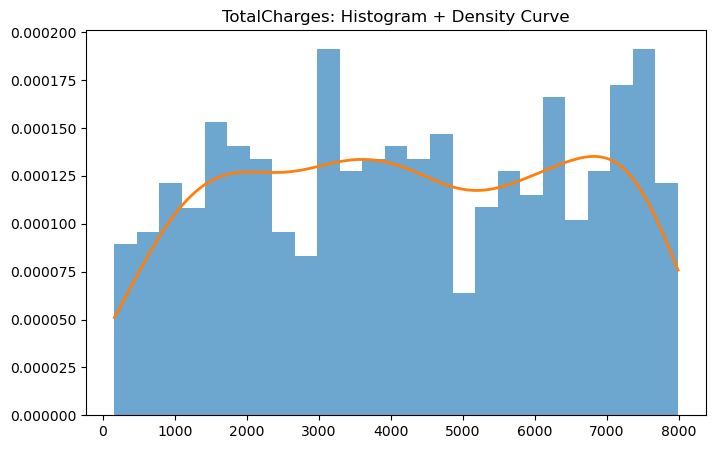

TotalCharges ShapiroResult(statistic=0.951427678533943, pvalue=9.382971874467683e-12)


In [3]:
for col in ['Tenure','MonthlyCharges','TotalCharges']:
    plt.figure(figsize=(8,5))
    plt.hist(df[col],bins=25,density=True,alpha=.65)
    xs=np.linspace(df[col].min(),df[col].max(),300)
    plt.plot(xs,stats.gaussian_kde(df[col])(xs),linewidth=2)
    plt.title(f'{col}: Histogram + Density Curve')
    plt.show()
    print(col, stats.shapiro(df[col]))

,Tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn
Tenure,1.000000,-0.059655,-0.005677,-0.040001,-0.509208
MonthlyCharges,-0.059655,1.000000,-0.042280,-0.105695,0.107381
TotalCharges,-0.005677,-0.042280,1.000000,0.016360,0.004250
SeniorCitizen,-0.040001,-0.105695,0.016360,1.000000,-0.018114
Churn,-0.509208,0.107381,0.004250,-0.018114,1.000000


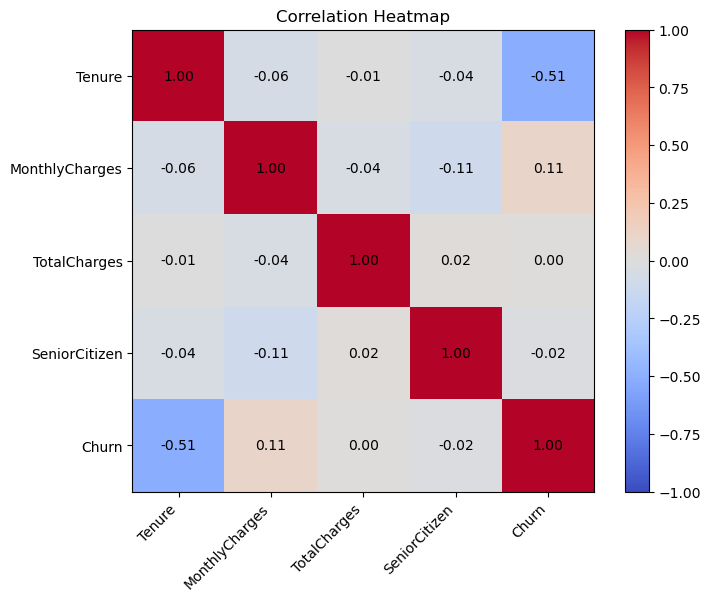

In [4]:
corr=df[numeric].corr()
display(corr)
plt.figure(figsize=(8,6)); plt.imshow(corr.values,cmap='coolwarm',vmin=-1,vmax=1); plt.colorbar()
plt.xticks(range(len(corr)),corr.columns,rotation=45,ha='right'); plt.yticks(range(len(corr)),corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)): plt.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center')
plt.title('Correlation Heatmap'); plt.show()

In [5]:
# Test 1: Monthly charges by churn
print(stats.ttest_ind(df.loc[df.Churn==0,'MonthlyCharges'],df.loc[df.Churn==1,'MonthlyCharges'],equal_var=False))
# Test 2: Tenure by churn
print(stats.ttest_ind(df.loc[df.Churn==0,'Tenure'],df.loc[df.Churn==1,'Tenure'],equal_var=False))
# Test 3: Monthly charges across contract types
print(stats.f_oneway(*[g['MonthlyCharges'].values for _,g in df.groupby('Contract')]))

TtestResult(statistic=-2.646439327283195, pvalue=0.010079197699533079, df=68.62719140566742)
TtestResult(statistic=34.53490213270181, pvalue=8.982326405691704e-130, df=459.5019503207317)
F_onewayResult(statistic=0.031273512548331085, pvalue=0.9692123527253496)


In [6]:
for col in ['Tenure','MonthlyCharges','TotalCharges']:
    x=df[col]; mean=x.mean(); ci=stats.t.interval(.95,len(x)-1,loc=mean,scale=stats.sem(x))
    print(f'{col}: mean={mean:.2f}, 95% CI=({ci[0]:.2f}, {ci[1]:.2f}), margin of error={(ci[1]-ci[0])/2:.2f}')

Tenure: mean=36.53, 95% CI=(34.72, 38.35), margin of error=1.82
MonthlyCharges: mean=113.64, 95% CI=(109.08, 118.19), margin of error=4.55
TotalCharges: mean=4237.88, 95% CI=(4039.25, 4436.51), margin of error=198.63


In [7]:
X=sm.add_constant(df[['Tenure','MonthlyCharges']]); y=df['TotalCharges']
model=sm.OLS(y,X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           TotalCharges   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                 -0.002
Method:                 Least Squares   F-statistic:                    0.4618
Date:                Fri, 25 Sep 2026   Prob (F-statistic):              0.630
Time:                        10:02:12   Log-Likelihood:                -4570.2
No. Observations:                 500   AIC:                             9146.
Df Residuals:                     497   BIC:                             9159.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const           4482.8713    311.064     14.